# Análise Min-Max e avaliação na base de teste

Objetivo deste notebook:
1. Ver se a **normalização min-max** (aprendida no treino) funciona bem nos dados de teste e de aplicação;
2. Comparar caminhos possíveis de tratamento dos dados;
3. Calcular o **desempenho esperado** (validação cruzada no treino) e o **desempenho real** (base de teste).

O modelo é o mesmo da API (`app/main.py`): min-max + regressão linear, prevendo `time` a partir de `time-5` ... `time-1`.

> Coloque `PI_train.csv`, `PI_test-1.csv` e `PI_application-1.csv` na mesma pasta deste notebook.

In [34]:
  # %pip install pandas numpy matplotlib scikit-learn

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

FEATURES = ["time-5", "time-4", "time-3", "time-2", "time-1"]
ALVO = "time"


## 1. Leitura das bases

In [36]:
treino = pd.read_csv("PI_train.csv")
teste = pd.read_csv("PI_test-1.csv")
aplicacao = pd.read_csv("PI_application-1.csv")

print("Treino:", treino.shape, "| Teste:", teste.shape, "| Aplicação:", aplicacao.shape)
print("Valores faltando -> treino:", treino.isna().sum().sum(),
      "| teste:", teste.isna().sum().sum(),
      "| aplicação:", aplicacao.isna().sum().sum())
treino.head()

Treino: (265, 6) | Teste: (114, 6) | Aplicação: (114, 5)
Valores faltando -> treino: 0 | teste: 0 | aplicação: 0


,time-5,time-4,time-3,time-2,time-1,time
0,96.5,61.1,41.0,52.6,5.6,1.2
1,181.4,97.0,543.0,203.2,218.9,101.4
2,0.0,33.4,113.0,66.5,232.8,267.9
3,71.4,59.4,123.4,271.3,114.0,120.0
4,349.6,489.0,201.8,61.0,147.6,8.8


## 2. Faixas (mínimo e máximo) de cada coluna

O min-max transforma cada valor em `(x - mín) / (máx - mín)`, usando o mínimo e o máximo **do treino**.
Se o teste tiver valores maiores que o máximo do treino, eles ficam **acima de 1** depois da normalização.

In [37]:
faixas = pd.DataFrame({
    "min_treino": treino.min(),
    "max_treino": treino.max(),
    "min_teste": teste.min(),
    "max_teste": teste.max(),
    "min_aplicacao": aplicacao.min(),
    "max_aplicacao": aplicacao.max(),
})
faixas

,min_treino,max_treino,min_teste,max_teste,min_aplicacao,max_aplicacao
time,0.0,543.0,0.0,718.0,NaN,NaN
time-1,0.0,718.0,0.0,509.2,0.0,509.2
time-2,0.0,718.0,0.0,509.2,0.0,509.2
time-3,0.0,718.0,0.0,509.2,0.0,509.2
time-4,0.0,543.0,0.0,718.0,0.0,718.0
time-5,0.0,718.0,0.0,515.0,0.0,515.0


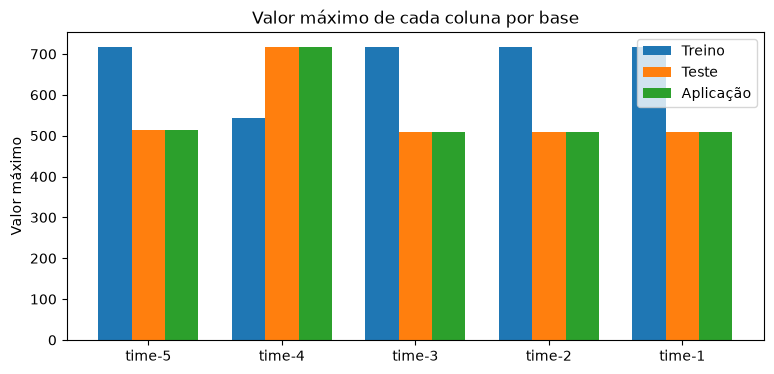

In [38]:
posicoes = np.arange(len(FEATURES))
largura = 0.25

plt.figure(figsize=(9, 4))
plt.bar(posicoes - largura, treino[FEATURES].max(), largura, label="Treino")
plt.bar(posicoes, teste[FEATURES].max(), largura, label="Teste")
plt.bar(posicoes + largura, aplicacao[FEATURES].max(), largura, label="Aplicação")
plt.xticks(posicoes, FEATURES)
plt.ylabel("Valor máximo")
plt.title("Valor máximo de cada coluna por base")
plt.legend()
plt.show()

## 3. Aplicando o min-max do treino nas outras bases

Aprendemos o mínimo/máximo **só no treino** e aplicamos nas outras bases (como a API faz).
Depois contamos quantos valores ficaram **fora do intervalo [0, 1]**.

In [39]:
scaler = MinMaxScaler()
scaler.fit(treino[FEATURES])

teste_norm = pd.DataFrame(scaler.transform(teste[FEATURES]), columns=FEATURES)
aplic_norm = pd.DataFrame(scaler.transform(aplicacao[FEATURES]), columns=FEATURES)

fora = pd.DataFrame({
    "teste_acima_de_1": (teste_norm > 1).sum(),
    "teste_abaixo_de_0": (teste_norm < 0).sum(),
    "aplicacao_acima_de_1": (aplic_norm > 1).sum(),
    "aplicacao_abaixo_de_0": (aplic_norm < 0).sum(),
})
print("Linhas do teste com algum valor fora de [0, 1]:", ((teste_norm > 1) | (teste_norm < 0)).any(axis=1).sum())
print("Linhas da aplicação com algum valor fora de [0, 1]:", ((aplic_norm > 1) | (aplic_norm < 0)).any(axis=1).sum())
fora

Linhas do teste com algum valor fora de [0, 1]: 1
Linhas da aplicação com algum valor fora de [0, 1]: 1


,teste_acima_de_1,teste_abaixo_de_0,aplicacao_acima_de_1,aplicacao_abaixo_de_0
time-5,0,0,0,0
time-4,1,0,1,0
time-3,0,0,0,0
time-2,0,0,0,0
time-1,0,0,0,0


In [40]:
print("Maior valor normalizado no teste:", round(teste_norm.max().max(), 3))
print("Maior valor normalizado na aplicação:", round(aplic_norm.max().max(), 3))
print()
print("Maior 'time' do treino:", treino[ALVO].max(), "| maior 'time' do teste:", teste[ALVO].max())
print("Linhas do teste com 'time' acima do máximo do treino:", (teste[ALVO] > treino[ALVO].max()).sum())

Maior valor normalizado no teste: 1.322
Maior valor normalizado na aplicação: 1.322

Maior 'time' do treino: 543.0 | maior 'time' do teste: 718.0
Linhas do teste com 'time' acima do máximo do treino: 1


## 4. Comparando caminhos de tratamento

Testamos 3 caminhos, todos com regressão linear:

| Caminho | O que faz |
|---|---|
| **A - Sem normalização** | usa os valores originais |
| **B - Min-max** | normaliza com mín/máx do treino (o que a API faz hoje) |
| **C - Min-max com corte** | normaliza e depois "corta" valores fora de [0, 1] (ex.: 1,32 vira 1) |

Para cada um calculamos:
- **Desempenho esperado**: média da validação cruzada 10-fold no treino (igual à API);
- **Desempenho real**: treino com 100% da base de treino e previsão na base de teste.

In [41]:
caminhos = {
    "A - Sem normalização": Pipeline([
        ("regressao", LinearRegression()),
    ]),
    "B - Min-max": Pipeline([
        ("minmax", MinMaxScaler()),
        ("regressao", LinearRegression()),
    ]),
    "C - Min-max com corte": Pipeline([
        ("minmax", MinMaxScaler()),
        ("corte", FunctionTransformer(lambda x: np.clip(x, 0, 1))),
        ("regressao", LinearRegression()),
    ]),
}

X_treino, y_treino = treino[FEATURES], treino[ALVO]
X_teste, y_teste = teste[FEATURES], teste[ALVO]
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

resultados = []
previsoes = {}
for nome, modelo in caminhos.items():
    # Desempenho esperado (validação cruzada no treino)
    cv = cross_validate(modelo, X_treino, y_treino, cv=kfold,
                        scoring=["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"])
    # Desempenho real (treina com tudo e testa na base de teste)
    modelo.fit(X_treino, y_treino)
    pred = modelo.predict(X_teste)
    previsoes[nome] = pred

    resultados.append({
        "caminho": nome,
        "RMSE esperado": -cv["test_neg_root_mean_squared_error"].mean(),
        "RMSE real": np.sqrt(mean_squared_error(y_teste, pred)),
        "MAE esperado": -cv["test_neg_mean_absolute_error"].mean(),
        "MAE real": mean_absolute_error(y_teste, pred),
        "R² esperado": cv["test_r2"].mean(),
        "R² real": r2_score(y_teste, pred),
    })

tabela = pd.DataFrame(resultados).set_index("caminho").round(3)
tabela

,RMSE esperado,RMSE real,MAE esperado,MAE real,R² esperado,R² real
caminho,,,,,,
A - Sem normalização,84.259,112.963,63.673,82.063,0.408,0.311
B - Min-max,84.259,112.963,63.673,82.063,0.408,0.311
C - Min-max com corte,83.804,112.659,63.167,81.693,0.416,0.314


## 5. Gráficos: real × previsto (caminho B, o da API)

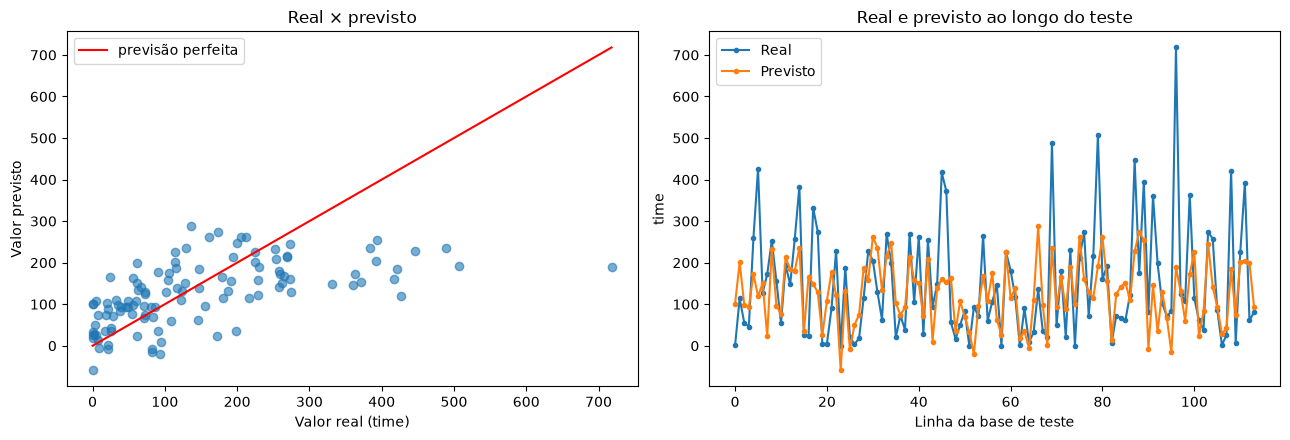

In [42]:
pred_b = previsoes["B - Min-max"]

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

# Dispersão: quanto mais perto da linha vermelha, melhor
eixos[0].scatter(y_teste, pred_b, alpha=0.6)
limite = max(y_teste.max(), pred_b.max())
eixos[0].plot([0, limite], [0, limite], color="red", label="previsão perfeita")
eixos[0].set_xlabel("Valor real (time)")
eixos[0].set_ylabel("Valor previsto")
eixos[0].set_title("Real × previsto")
eixos[0].legend()

# Linha a linha da base de teste
eixos[1].plot(y_teste.values, label="Real", marker=".")
eixos[1].plot(pred_b, label="Previsto", marker=".")
eixos[1].set_xlabel("Linha da base de teste")
eixos[1].set_ylabel("time")
eixos[1].set_title("Real e previsto ao longo do teste")
eixos[1].legend()

plt.tight_layout()
plt.show()

In [43]:
# Os maiores erros acontecem nas linhas fora da faixa do treino?
erro = np.abs(y_teste - pred_b)
linha_fora = ((teste_norm > 1) | (teste_norm < 0)).any(axis=1) | (teste[ALVO] > treino[ALVO].max())

print("Erro médio (MAE) nas linhas DENTRO da faixa do treino:", round(erro[~linha_fora].mean(), 2), f"({(~linha_fora).sum()} linhas)")
print("Erro médio (MAE) nas linhas FORA da faixa do treino:  ", round(erro[linha_fora].mean(), 2), f"({linha_fora.sum()} linhas)")

Erro médio (MAE) nas linhas DENTRO da faixa do treino: 77.79 (112 linhas)
Erro médio (MAE) nas linhas FORA da faixa do treino:   321.36 (2 linhas)


## 6. Previsões da base de aplicação (sem rótulo)

In [44]:
modelo_final = caminhos["B - Min-max"]
saida = aplicacao.copy()
saida["time_previsto"] = modelo_final.predict(aplicacao[FEATURES]).round(2)
saida.to_csv("previsoes_aplicacao.csv", index=False)
print("Arquivo salvo: previsoes_aplicacao.csv")
saida.head()

Arquivo salvo: previsoes_aplicacao.csv


,time-5,time-4,time-3,time-2,time-1,time_previsto
0,114.0,120.0,115.0,68.4,92.6,100.94
1,6.2,71.4,59.4,123.4,271.3,200.62
2,62.7,28.0,54.0,0.0,21.6,98.90
3,129.2,90.1,30.6,100.2,23.2,92.89
4,55.4,57.4,144.0,222.8,102.4,172.87


## 7. Conclusão

**1. O min-max não muda o resultado da regressão linear.** Os caminhos A e B dão métricas idênticas.
A regressão linear só "reescala" os coeficientes para compensar a normalização, então as previsões são as mesmas.
Mesmo assim, mantemos o min-max: o trabalho pede o tratamento, e com ele todas as colunas ficam na mesma escala, o que deixa os coeficientes comparáveis.

**2. Quase tudo do teste cabe na faixa do treino.** Só **1 valor** (`time-4` = 718, que vira 1,32 depois da normalização) passou do máximo do treino (543).
Cortar em [0, 1] (caminho C) melhora muito pouco (RMSE 112,7 contra 113,0). Não compensa complicar a API por isso.

**3. O desempenho real foi pior que o esperado** (RMSE 113 contra 84; R² 0,31 contra 0,41). O motivo não é a normalização:
- a base de teste tem valores maiores e mais variados (média de `time` 150 contra 116 no treino);
- há picos que o modelo não consegue prever, como `time` = 718, acima de tudo o que existe no treino.
  As 2 linhas fora da faixa têm erro médio de cerca de 321, contra cerca de 78 nas demais.

**Caminho escolhido:** manter o **caminho B (min-max + regressão linear)**, que é o que a API já faz.
Como próximo passo, a rota `/predict` deve **avisar quantos valores estão fora da faixa do treino**, porque essas linhas tendem a ter erro maior.